# Figure 5 of Pucha et al. (2026)

In [1]:
import numpy as np
import pandas as pd

from astropy.table import Table, Column

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from scipy.ndimage import gaussian_filter

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.5,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.5,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
## Read in the BL-AGN Candidates
t = Table.read('../catalogs/iron-blagn-selection.fits')

In [4]:
## Stellar Mass and Black Hole Mass

logmass = t['LOGM'].data
logmass_err = t['LOGM_ERR'].data

bh_mass = t['LOG_MBH'].data
bh_mass_err = t['LOG_MBH_ERR'].data

z = t['Z'].data

In [5]:
## Morphology related variables
mtype = t['TYPE'].astype(str).data
is_psf = (mtype == 'PSF')

### Overmassive BHs from Literature

In [6]:
## Overmeassive Black Holes from z~0.35 to z~7

## VIPERS Lowz
vipers_lowz = pd.read_csv('../catalogs/other_cats/Mezcua2023.txt', header = 0, sep=r"[,\t]+")
## Put all -- to nans
vipers_lowz = vipers_lowz.replace('--', np.nan)

## VIPERS High-z
vipers_highz = pd.read_csv('../catalogs/other_cats/Mezcua2024.txt', header = 0, sep=r"[,\t]+")
## Put all -- to nans
vipers_highz = vipers_highz.replace('--', np.nan)
vipers_highz['logBHmass'] = vipers_highz['logBHmass'].astype(np.float16)
vipers_highz['logBHmass_err'] = vipers_highz['logBHmass_err'].astype(np.float16)

## JWST compilation 
## Used in Pacucci+2023 fit
jwst_p23 = pd.read_csv('../catalogs/other_cats/JWST_Pacucci.txt', header = 0, sep=r"[,\t]+", comment = '%')
#Add arrows for upper limits on stellar mass
jwst_uplim_p23 = (jwst_p23['logMstar_eu']==-99.00)
jwst_mstar_uplimit_p23 = jwst_p23[jwst_uplim_p23]

## Other Studies
jwst_oth = pd.read_csv('../catalogs/other_cats/JWST_dataALL.txt', header = 0, sep=r"[,\t]+", comment = '%')
#Add arrows for upper limits on stellar mass
jwst_uplim_oth = (jwst_oth['logMstar_eu']==-99.00)
jwst_mstar_uplimit_oth = jwst_oth[jwst_uplim_oth]

In [7]:
def overplot_highz_points(axs = None, size = 50, label = True):

    if (axs == None):
        axs = plt.gca()

    if (label == True):
        ## VIPERS Low-z (Mezcua et al. 2023)
        axs.scatter(vipers_lowz['logMstellar'],vipers_lowz['logBHmass'],s=size, edgecolor='k', marker='s', color='gold', label='Mezcua+2023, z$\sim$0.4 $-$ 0.9', zorder = 3)
    else:
        ## VIPERS Low-z (Mezcua et al. 2023)
        axs.scatter(vipers_lowz['logMstellar'],vipers_lowz['logBHmass'],s=size, edgecolor='k', marker='s', color='gold', zorder = 3)
    #Plot error bars
    xerr=[np.abs(vipers_lowz['logMstellar_lerr']),vipers_lowz['logMstellar_uerr']]
    yerr = [vipers_lowz['logBHmass_err'], vipers_lowz['logBHmass_err']]
    axs.errorbar(vipers_lowz['Ms(best)'], vipers_lowz['logBHmass'], yerr=yerr, xerr=xerr, fmt='none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## VIPERS High-z (Mezcua et al. 2024)
        axs.scatter(vipers_highz['logMstellar'],vipers_highz['logBHmass'],s=size+20, edgecolor='k', marker='o', color='lime', label='Mezcua+2024, z$\sim$1 $-$ 3', zorder = 3)
    else:
        ## VIPERS High-z (Mezcua et al. 2024)
        axs.scatter(vipers_highz['logMstellar'],vipers_highz['logBHmass'],s=size+20, edgecolor='k', marker='o', color='lime', zorder = 3)
    #Plot error bars
    xerr=[np.abs(vipers_highz['logMstellar_lerr']),vipers_highz['logMstellar_uerr']]
    yerr = [vipers_highz['logBHmass_err'], vipers_highz['logBHmass_err']]
    axs.errorbar(vipers_highz['Ms(best)'], vipers_highz['logBHmass'], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## JWST Used in Paccucci+2023 fit
        axs.scatter(jwst_p23['logMstar'], jwst_p23['logMbh'], s=size, edgecolor='k', marker='D', color='m', label='JWST, z$\sim$4 $-$ 8', zorder = 2)
    else:
        ## JWST Used in Paccucci+2023 fit
        axs.scatter(jwst_p23['logMstar'], jwst_p23['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    axs.scatter(jwst_mstar_uplimit_p23['logMstar']-0.07, jwst_mstar_uplimit_p23['logMbh']-0.01, s=3*size, edgecolor='k', marker=r'$\leftarrow$', alpha = 0.3, zorder = 3)
    #Plot error bars
    xerr = [jwst_p23['logMstar_el'][~jwst_uplim_p23],jwst_p23['logMstar_eu'][~jwst_uplim_p23]]
    yerr = [jwst_p23['logMbh_el'][~jwst_uplim_p23], jwst_p23['logMbh_eu'][~jwst_uplim_p23]]
    axs.errorbar(jwst_p23['logMstar'][~jwst_uplim_p23], jwst_p23['logMbh'][~jwst_uplim_p23], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## JWST Others
        axs.scatter(jwst_oth['logMstar'], jwst_oth['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    else:
        ## JWST Others
        axs.scatter(jwst_oth['logMstar'], jwst_oth['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    axs.scatter(jwst_mstar_uplimit_oth['logMstar']-0.07, jwst_mstar_uplimit_oth['logMbh']-0.01, s=3*size, edgecolor='k', marker=r'$\leftarrow$', alpha = 0.3, zorder = 3)
    #Plot error bars
    xerr = [jwst_oth['logMstar_el'][~jwst_uplim_oth], jwst_oth['logMstar_eu'][~jwst_uplim_oth]]
    yerr = [jwst_oth['logMbh_el'][~jwst_uplim_oth], jwst_oth['logMbh_eu'][~jwst_uplim_oth]]
    axs.errorbar(jwst_oth['logMstar'][~jwst_uplim_oth], jwst_oth['logMbh'][~jwst_uplim_oth], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

### Fit Related Functions and Variables

In [8]:
def mstar_to_bh(mass, a, b):
    term1 = b*np.log10(mass/1e+11)
    yy = a + term1
    
    return (yy)

In [9]:
def mstar_mbh_p23(mass):
    term1 = 1.06*np.log10(mass)
    log_mbh = -2.43 + term1

    return (log_mbh)

In [10]:
def mstar_mbh_suh2020(mass):
    term1 = 1.64*np.log10(mass)
    term2 = -10.29
    
    mbh = term1 + term2
    
    return (mbh)

In [11]:
def mstar_mbh_greene2020(mass, a = 7.56, b = 1.39, e = 0.79):
    term1 = a
    term2 = b*np.log10(mass/3e+10)

    mbh = term1 + term2

    return (mbh)

In [12]:
def mbh_mstar_lines(mstar, m):
    mbh = m*mstar
    return (mbh)

In [13]:
mass_xx = np.logspace(6, 13, 1000)
mbh_early = mstar_to_bh(mass_xx, a = 8.95, b = 1.40)
mbh_late = mstar_to_bh(mass_xx, a = 7.45, b = 1.05)
mbh_p25 = mstar_to_bh(mass_xx, a = 7.66, b = 1.15)
mbh_p23 = mstar_mbh_p23(mass_xx)
mbh_g20 = mstar_mbh_greene2020(mass_xx, a = 7.43, b = 1.61, e = 0.81)
mbh_suh2020 = mstar_mbh_suh2020(mass_xx)

In [14]:
def add_literature_fits(axs = None, pucha25 = True, pacucci23 = True, greene20 = True, suh20 = True,\
                        r13_late = True, r13_early = True, linewidth = 3.0, label = False):

    if (axs == None):
        axs = plt.gca()

    if (label == False):
        jwst_kwargs = {'color' : 'm', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 2, 'alpha' : 0.5}
        p25_kwargs = {'color' : 'tomato', 'linestyle' : '-.', 'linewidth' : linewidth, 'zorder' : 2}
        r13_late_kwargs = {'color' : 'steelblue', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 1, 'alpha' : 0.5}
        r13_early_kwargs = {'color': 'dimgray', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 1}
        g20_kwargs = {'color': 'goldenrod', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 2}
        suh_kwargs = {'color': 'goldenrod', 'linestyle' : '-', 'linewidth' : linewidth, 'zorder' : 2}
    else:
        jwst_kwargs = {'color' : 'm', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 2, 'alpha' : 0.5, 'label' : 'Pacucci+2023'}
        p25_kwargs = {'color' : 'tomato', 'linestyle' : '-.', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Pucha+2025'}
        r13_late_kwargs = {'color' : 'steelblue', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 1, 'alpha': 0.5, 'label' : 'Reines+2015'}
        r13_early_kwargs = {'color': 'dimgray', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 1, 'label' : 'Reines+2015 (Early)'}
        g20_kwargs = {'color': 'goldenrod', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Greene+2020'}
        suh_kwargs = {'color': 'goldenrod', 'linestyle' : '-', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Suh+2020'}

    if (pucha25 == True):
        axs.plot(np.log10(mass_xx), mbh_p25, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_p25, **p25_kwargs)
        
    if (pacucci23 == True):
        axs.plot(np.log10(mass_xx), mbh_p23, color = 'white', lw = linewidth, zorder = 2)
        axs.plot(np.log10(mass_xx), mbh_p23, **jwst_kwargs)

    if (greene20 == True):
        axs.plot(np.log10(mass_xx), mbh_g20, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_g20, **g20_kwargs)

    if (suh20 == True):
        axs.plot(np.log10(mass_xx), mbh_suh2020, color = 'white', lw = linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_suh2020, **suh_kwargs)

    if (r13_late == True):
        axs.plot(np.log10(mass_xx), mbh_late, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_late, **r13_late_kwargs)

    if (r13_early == True):
        axs.plot(np.log10(mass_xx), mbh_early, color = 'white', lw = linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_early, **r13_early_kwargs)    

### Fits

In [15]:
a_ext, aerr_ext, b_ext, berr_ext = (7.627269683880347, 0.006563102420785898, 1.019242500318526, 0.012071992317511073)
a_psf, aerr_psf, b_psf, berr_psf = (8.461820747292254, 0.035128579807597496, 1.0330915349989231, 0.03781416049520155)
a_all, aerr_all, b_all, berr_all = (7.655680636813742, 0.00704660366300485, 0.8958283811998237, 0.012244683806455287)

In [16]:
mbh_ext = mstar_to_bh(mass_xx, a = a_ext, b = b_ext)
mbh_psf = mstar_to_bh(mass_xx, a = a_psf, b = b_psf)
mbh_all = mstar_to_bh(mass_xx, a = a_all, b = b_all)

In [17]:
dens1, _, _ = np.histogram2d(logmass[~is_psf], bh_mass[~is_psf], \
                         bins=70, range = [[8, 12.5], [3.8, 10]], density = True)

dens2, _, _ = np.histogram2d(logmass[is_psf], bh_mass[is_psf], \
                        bins=50, range = [[8, 12.5], [3.8, 10]], density = True)

## Apply Gaussian filter to smooth the density arrays
dens1_smooth = gaussian_filter(dens1, sigma = 1.5)
dens2_smooth = gaussian_filter(dens2, sigma = 1.5)

In [18]:
## Greene, Strader, and Ho (2020)

logmass_g20 = np.array([10.1, 10.2, 10.2, 10.2, 10.2, 10.3, 10.3, 10.3, 10.4, 10.4, 10.5, 10.5, 10.5, 10.5, 10.5, 10.5, \
                        10.6, 10.6, 10.6, 10.6, 10.6, 10.6, 10.7, 10.7, 10.7, 10.7, 10.7, 10.7, 10.8, 10.8, 10.8, 10.8, \
                        10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.9, 10.9, 10.9, 10.9, 10.9, \
                        10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 11, 11, 11, 11, 11, 11, \
                        11, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.2, 11.2, 11.2, 11.2, 11.2, 11.2, 11.2, 11.3, \
                        11.3, 11.3, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.5, 11.5, 11.5, 11.5, 11.5, 11.5, \
                        11.5, 11.5, 11.5, 11.6, 11.6, 11.6, 11.6, 11.6, 11.6, 11.7, 11.7, 11.7, 11.8, 11.8, 11.9])

bhmass_g20 = np.array([7.61, 7.63, 7.16, 7.16, 6.95, 7.85, 7.28, 6.06, 8.69, 8.66, 8.25, 8.26, 7.94, 7.65, 6.77, \
                       6.86, 7.83, 8.77, 8.93, 8.36, 6.83, 6.13, 8.00, 6.85, 8.99, 7.03, 7.88, 7.88, 7.81, 6.40, \
                       7.81, 8.62, 7.95, 7.84, 7.62, 8.38, 6.94, 8.16, 7.81, 7.58, 6.94, 6.88, 6.19, 8.60, 8.11, \
                       6.74, 8.23, 6.93, 8.73, 8.70, 8.67, 8.31, 8.44, 8.22, 7.85, 8.95, 7.88, 7.32, 6.70, 6.98, \
                       8.40, 7.36, 9.23, 7.03, 7.76, 7.20, 7.74, 7.41, 7.89, 8.60, 9.17, 9.32, 10.23, 8.65, 7.30, \
                       8.26, 9.59, 8.93, 8.14, 8.94, 8.52, 9.45, 9.04, 6.92, 8.04, 8.00, 8.85, 8.51, 8.94, 9.57, \
                       7.11, 8.82, 9.57, 8.97, 9.67, 9.68, 9.57, 9.36, 9.39, 8.72, 8.60, 9.67, 9.96, 9.79, 9.13, \
                       9.57, 9.11, 9.11, 10.23, 9.40, 9.86, 8.23, 10.32])

In [19]:
ext_kwargs = {'color' : 'k', 'linestyle' : '-', 'zorder' : 3}

In [20]:
clevels = list(np.logspace(np.log10(0.02), np.log10(0.8), 6))

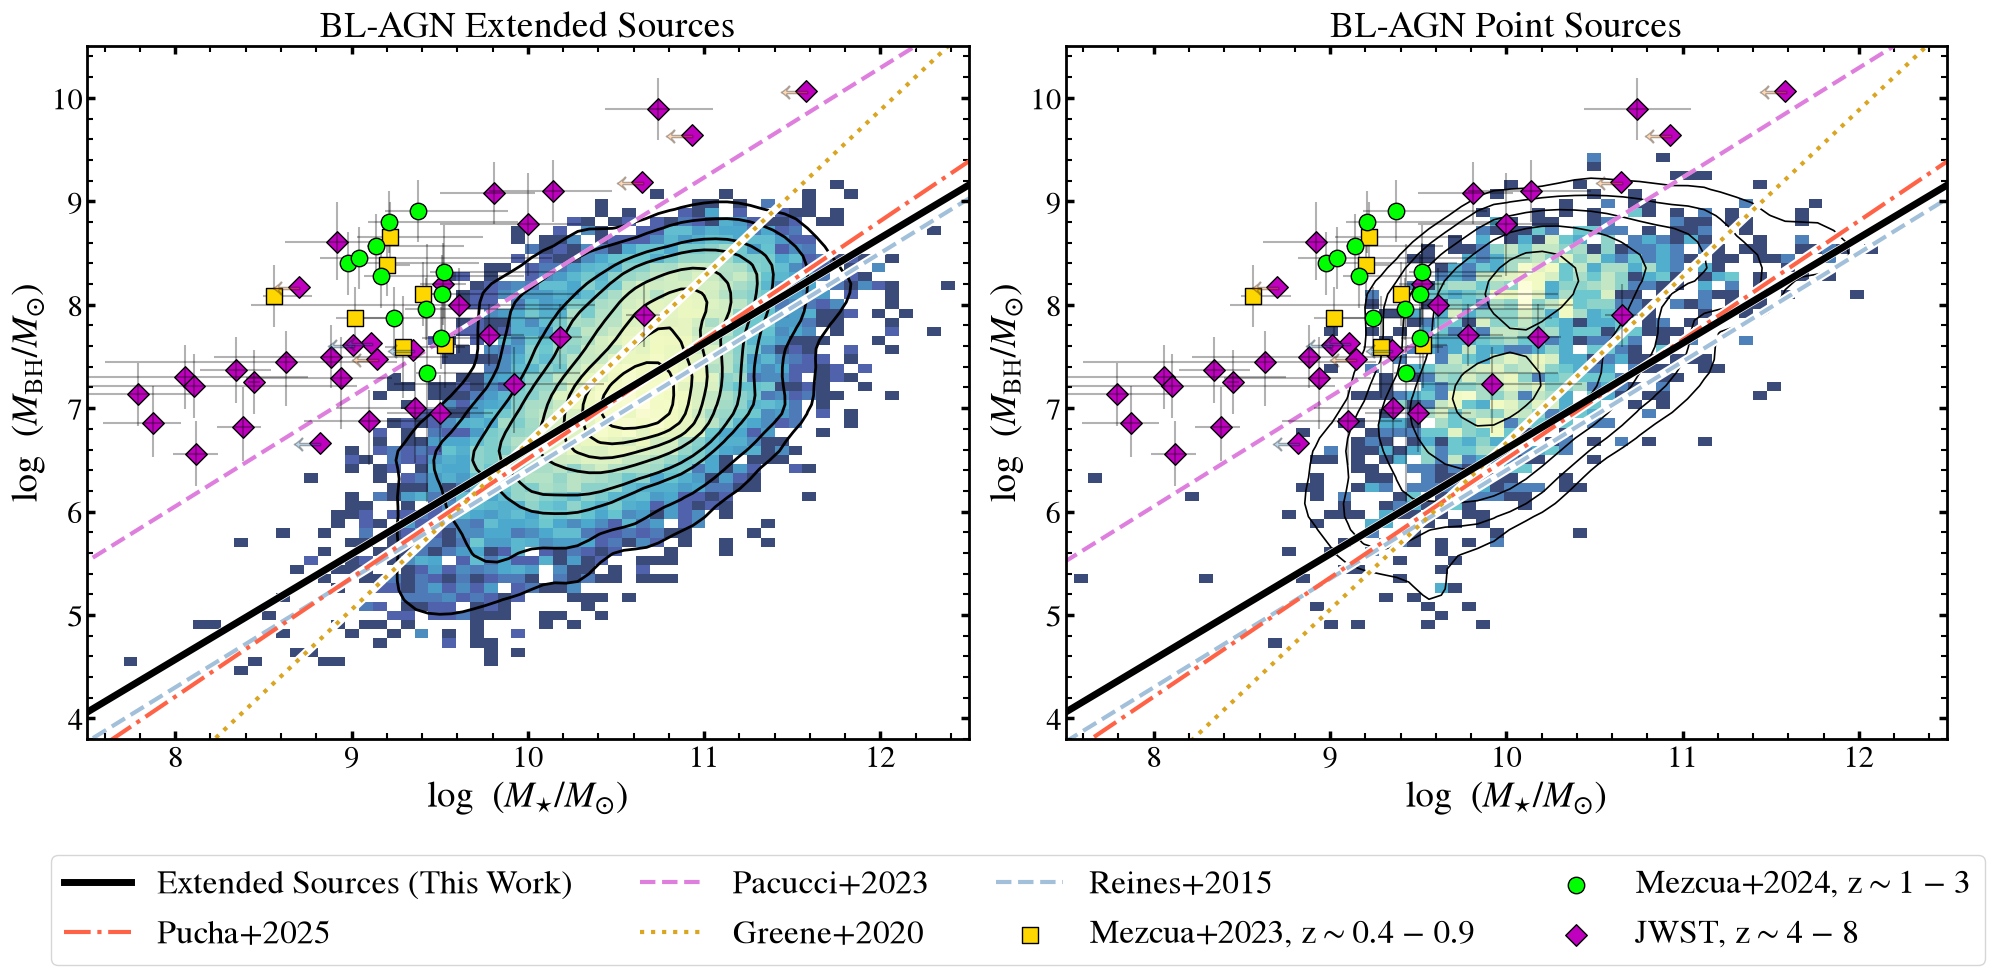

In [21]:
plt.figure(figsize = (24, 9))
plt.subplots_adjust(wspace = 0.11)

plt.subplot2grid((1,2), (0,0))
plt.hist2d(logmass[~is_psf], bh_mass[~is_psf], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
plt.contour(dens1_smooth.T, levels = [0.015, 0.04, 0.1, 0.15, 0.25, 0.35, 0.45, 0.55], \
            extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 2.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, lw = 5, **ext_kwargs)
add_literature_fits(r13_early=False, suh20 = False, label = False)
overplot_highz_points(size = 120, label = False)
plt.gca().set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$',\
              ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$', title = 'BL-AGN Extended Sources')

plt.subplot2grid((1,2), (0,1))
plt.hist2d(logmass[is_psf], bh_mass[is_psf], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
plt.contour(dens2_smooth.T, levels = clevels, extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 1.2, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, lw = 5, label = 'Extended Sources (This Work)', **ext_kwargs)
add_literature_fits(r13_early = False,  suh20 = False, label = True)
overplot_highz_points(size = 120, label = True)
plt.gca().set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$', \
        ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$', title = 'BL-AGN Point Sources')
plt.legend(loc = 'lower left', fontsize = 24, frameon = True, ncol = 4, bbox_to_anchor = (-1.17,-0.35))

# plt.savefig('mbh-mstar.png', bbox_inches = 'tight')

---